# 📊 Gym Dataset Visualization Assignment

This notebook completes the **Matplotlib** and **Seaborn** visualization tasks using the Gym Members dataset.

### Assignment Tasks
**Matplotlib**
1. Bar chart of membership types — `gym['abonoment_type'].value_counts()`
2. Histogram of `avg_time_in_gym`
3. Scatter plot of `Age` vs `visit_per_week`

**Seaborn**
1. Box plot — `gender` vs `Age`
2. Count plot — `days_per_week`
3. Bar plot — mean `visit_per_week` per `abonoment_type`

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside the notebook
%matplotlib inline

# Optional: make Seaborn plots look cleaner
sns.set_theme(style='whitegrid')

In [4]:
from google.colab import files

uploaded = files.upload()

# Get the uploaded filename
file_name = next(iter(uploaded))

# Read the CSV file
gym = pd.read_csv(file_name)

print('Dataset loaded successfully!')
print('Shape:', gym.shape)
gym.head()

Saving gym_membership.csv to gym_membership.csv
Dataset loaded successfully!
Shape: (1000, 17)


,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,fav_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,fav_drink,personal_training,name_personal_trainer,uses_sauna
0,1,Female,4/18/1997,27,Premium,4,"Mon, Sat, Tue, Wed",True,"Kickboxen, BodyPump, Zumba",19:31:00,21:27:00,116,False,NaN,False,NaN,True
1,2,Female,9/18/1977,47,Standard,3,"Mon, Sat, Wed",False,NaN,19:31:00,20:19:00,48,False,NaN,True,Chantal,False
2,3,Male,3/30/1983,41,Premium,1,Sat,True,XCore,8:29:00,10:32:00,123,True,"berry_boost, lemon",True,Mike,False
3,4,Male,4/12/1980,44,Premium,3,"Sat, Tue, Wed",False,NaN,9:54:00,11:33:00,99,True,passion_fruit,True,Mike,True
4,5,Male,9/10/1980,44,Standard,2,"Thu, Wed",True,"Running, Yoga, Zumba",8:29:00,9:19:00,50,False,NaN,True,Mike,False


In [5]:
print('Columns in the dataset:')
print(gym.columns.tolist())

print('\nDataset information:')
gym.info()

Columns in the dataset:
['id', 'gender', 'birthday', 'Age', 'abonoment_type', 'visit_per_week', 'days_per_week', 'attend_group_lesson', 'fav_group_lesson', 'avg_time_check_in', 'avg_time_check_out', 'avg_time_in_gym', 'drink_abo', 'fav_drink', 'personal_training', 'name_personal_trainer', 'uses_sauna']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     1000 non-null   int64 
 1   gender                 1000 non-null   object
 2   birthday               1000 non-null   object
 3   Age                    1000 non-null   int64 
 4   abonoment_type         1000 non-null   object
 5   visit_per_week         1000 non-null   int64 
 6   days_per_week          1000 non-null   object
 7   attend_group_lesson    1000 non-null   bool  
 8   fav_group_lesson       503 non-null    object
 9   av

# Matplotlib Visualizations

## Bar Chart of Membership Types

This chart shows how many gym members have each membership type.

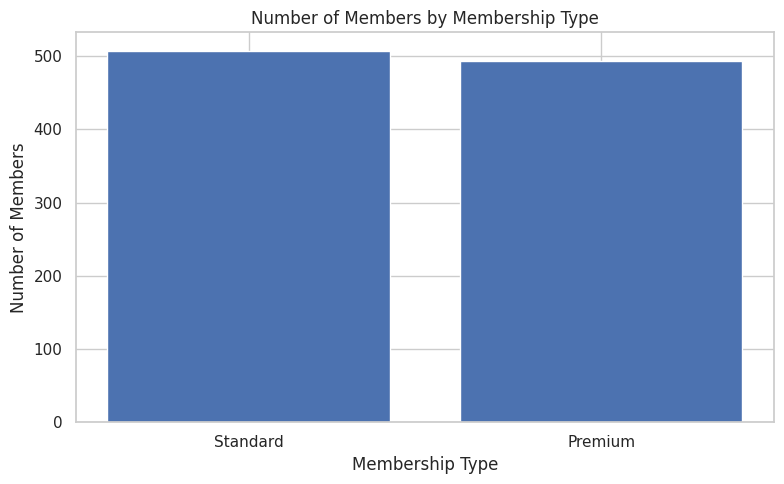

In [12]:
# Count each membership type
membership_counts = gym['abonoment_type'].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(membership_counts.index, membership_counts.values)

plt.title('Number of Members by Membership Type')
plt.xlabel('Membership Type')
plt.ylabel('Number of Members')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Answer / Observation

The bar chart compares the number of members in each membership category. The height of each bar represents the number of gym members belonging to that membership type.

## Histogram of `avg_time_in_gym`

A histogram is used to visualize the distribution of the average time members spend in the gym.

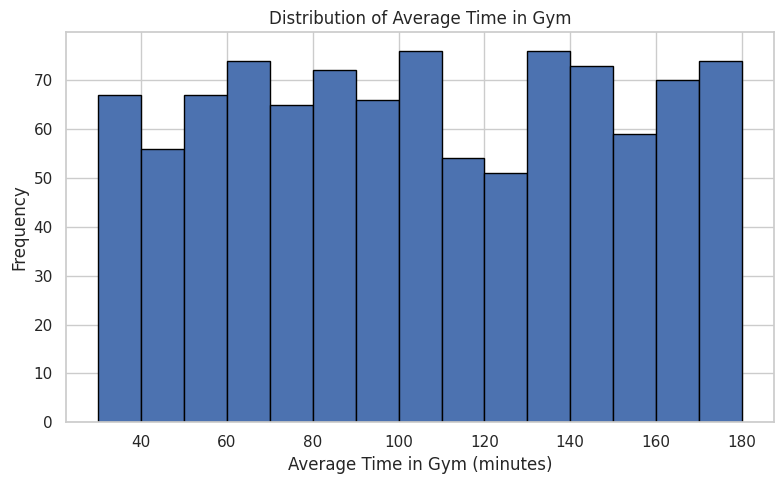

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(gym['avg_time_in_gym'].dropna(), bins=15, edgecolor='black')

plt.title('Distribution of Average Time in Gym')
plt.xlabel('Average Time in Gym (minutes)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Answer / Observation

The histogram shows how the members' average gym time is distributed. The x-axis represents time in minutes, while the y-axis represents the number of members.

## Scatter Plot: Age vs Visit per Week

This scatter plot helps visualize the relationship between members' age and how many times they visit the gym per week.

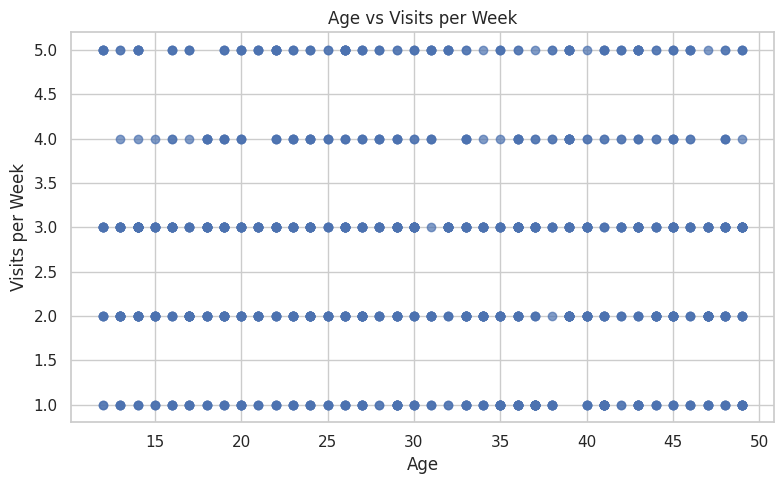

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(gym['Age'], gym['visit_per_week'], alpha=0.7)

plt.title('Age vs Visits per Week')
plt.xlabel('Age')
plt.ylabel('Visits per Week')
plt.tight_layout()
plt.show()

### Answer / Observation

Each point represents a gym member. The plot allows us to visually inspect whether age appears to be associated with the number of weekly gym visits.

# Seaborn Visualizations

## Box Plot: Gender vs Age

The box plot compares the age distribution between different genders.

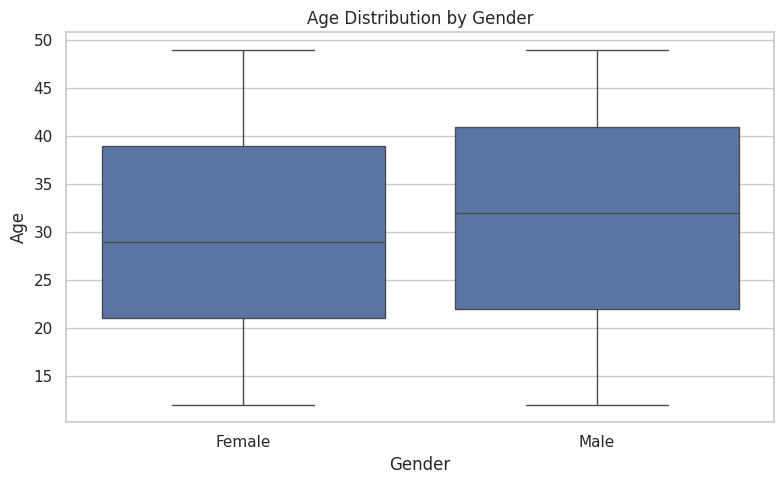

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=gym, x='gender', y='Age')

plt.title('Age Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.tight_layout()
plt.show()

### Answer / Observation

The box plot displays the median, spread, and potential outliers of age for each gender category.

## Count Plot: `days_per_week`

The `days_per_week` column contains the days on which each member visits the gym. Because a member can have multiple days in this field, the values are first split into individual days.

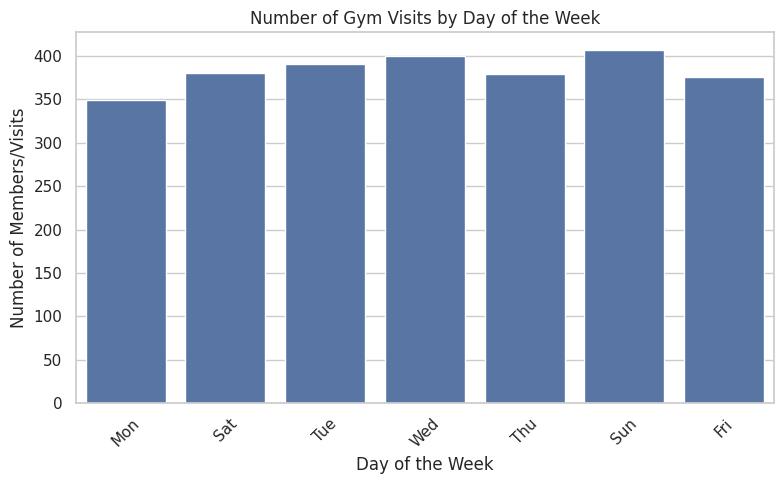

In [10]:
# Convert the comma-separated days into individual rows
days = gym['days_per_week'].dropna().astype(str).str.split(', ')
days = days.explode().str.strip()

plt.figure(figsize=(8, 5))

sns.countplot(x=days)

plt.title('Number of Gym Visits by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Members/Visits')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Answer / Observation

The count plot shows how frequently each day of the week appears in members' gym schedules.

## Bar Plot: Mean Visits per Week by Membership Type

This plot compares the average number of weekly gym visits for each membership type.

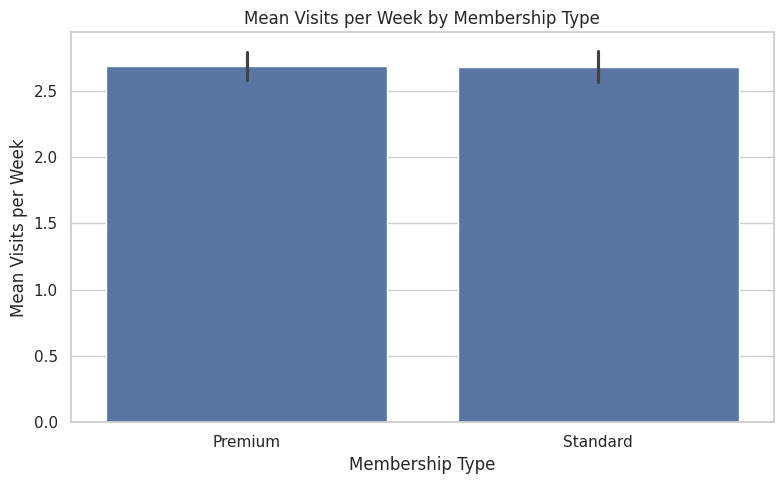

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gym,
    x='abonoment_type',
    y='visit_per_week',
    estimator='mean'
)

plt.title('Mean Visits per Week by Membership Type')
plt.xlabel('Membership Type')
plt.ylabel('Mean Visits per Week')
plt.tight_layout()
plt.show()

### Answer / Observation

The bar plot compares the mean weekly visit frequency between membership types. A taller bar indicates a higher average number of visits per week.